In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [2]:
pcaredo_df = pd.read_csv('/Users/maxbruggman/Downloads/BIMStatsRedo/BIM_counts(PCARedo).csv', index_col=0)
pcaredo_df.head()

,Abditodentrix sp.,Anomalinoides incrassatus,Bolivina earlandi,Bolivina seminuda,Bolivina sp.,Bolivina subspinescens,Bulimina aculeata,Bulimina marginata,Bulimina striata,Cassidulina spp.,...,Sed Rate (cm/kyr),Bulk AR (g/cm^2ky),AR Carbonate (g/cm^2ky),AR Siliciclastics (g/cm^2ky),AR Coarse Fraction ( >63 µm g/cm^2ky),AR Chlorine (g/cm^2ky),AR Aluminum (g/cm^2ky),AR Iron (g/cm^2ky),AR Titanium (g/cm^2ky),AR excess Barium (g/cm^2ky)
1171C1 (~15kyr),0.000000,0.000000,0.000000,0.147442,0.000000,0.000000,0.000000,0.085126,0.000000,0.085126,...,3.559,3.170,2.982,0.188,2.132,0.09,8.530,5.636,0.560,1.455
1171C2 (~36.429kyr),0.000000,0.068519,0.167836,0.068519,0.000000,0.000000,0.000000,0.000000,0.216676,0.137038,...,1.000,0.899,0.851,0.048,0.376,0.03,2.666,1.645,0.170,0.376
1171C3 (~72.143kyr),0.000000,0.000000,0.198030,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.198030,...,0.923,0.816,0.774,0.043,0.368,0.01,1.577,0.874,0.091,0.342
1171C4 (~115kyr),0.067267,0.000000,0.082385,0.000000,0.047565,0.047565,0.067267,0.000000,0.000000,0.352753,...,0.475,0.444,0.418,0.026,0.181,0.01,0.741,0.557,0.041,0.233


In [3]:
scaler = StandardScaler()

copy_pcaredo_df = pcaredo_df.copy()
scaled_copy_pcaredo = pd.DataFrame(
    scaler.fit_transform(copy_pcaredo_df),
    columns = copy_pcaredo_df.columns,
    index = copy_pcaredo_df.index
    )

scaled_copy_pcaredo.head()

,Abditodentrix sp.,Anomalinoides incrassatus,Bolivina earlandi,Bolivina seminuda,Bolivina sp.,Bolivina subspinescens,Bulimina aculeata,Bulimina marginata,Bulimina striata,Cassidulina spp.,...,Sed Rate (cm/kyr),Bulk AR (g/cm^2ky),AR Carbonate (g/cm^2ky),AR Siliciclastics (g/cm^2ky),AR Coarse Fraction ( >63 µm g/cm^2ky),AR Chlorine (g/cm^2ky),AR Aluminum (g/cm^2ky),AR Iron (g/cm^2ky),AR Titanium (g/cm^2ky),AR excess Barium (g/cm^2ky)
1171C1 (~15kyr),-0.577350,-0.577350,-1.448542,1.537678,-0.577350,-0.577350,-0.577350,1.732051,-0.577350,-1.076881,...,1.708180,1.709899,1.709236,1.718379,1.723657,1.677484,1.688168,1.699006,1.687525,1.722183
1171C2 (~36.429kyr),-0.577350,1.732051,0.720938,0.239058,-0.577350,-0.577350,-0.577350,-0.577350,1.732051,-0.559789,...,-0.403782,-0.403109,-0.401372,-0.434400,-0.489278,-0.152499,-0.233489,-0.261877,-0.222881,-0.455012
1171C3 (~72.143kyr),-0.577350,-0.577350,1.111221,-0.888368,-0.577350,-0.577350,-0.577350,-0.577350,-0.577350,0.047744,...,-0.467330,-0.480335,-0.477635,-0.511285,-0.499360,-0.762493,-0.590359,-0.640689,-0.609860,-0.523616
1171C4 (~115kyr),1.732051,-0.577350,-0.383616,-0.888368,1.732051,1.732051,1.732051,-0.577350,-0.577350,1.588926,...,-0.837068,-0.826455,-0.830228,-0.772694,-0.735020,-0.762493,-0.864320,-0.796440,-0.854784,-0.743555


In [4]:
pca_redo = PCA(n_components = 4, svd_solver='auto') # The fourth PC is not worth keeping, as it explains far less than one percent of the overall variance.
pc_redo_comps = pca_redo.fit_transform(scaled_copy_pcaredo)

pc_redo_comps_df = pd.DataFrame(
    data = pc_redo_comps,
    columns = [f'PC{i+1}' for i in range(pca_redo.n_components_)],
    index = copy_pcaredo_df.index
)

pc_redo_comps_df.head()

,PC1,PC2,PC3,PC4
1171C1 (~15kyr),9.851985,-5.147143,-0.776337,1.623459e-15
1171C2 (~36.429kyr),-0.280753,7.945865,-6.028627,1.623459e-15
1171C3 (~72.143kyr),-1.009856,3.837572,8.503688,1.623459e-15
1171C4 (~115kyr),-8.561375,-6.636293,-1.698723,1.623459e-15


In [5]:
print(pca_redo.explained_variance_)

[5.71524616e+01 4.94657308e+01 3.73818076e+01 3.51415803e-30]


<function matplotlib.pyplot.show(close=None, block=None)>

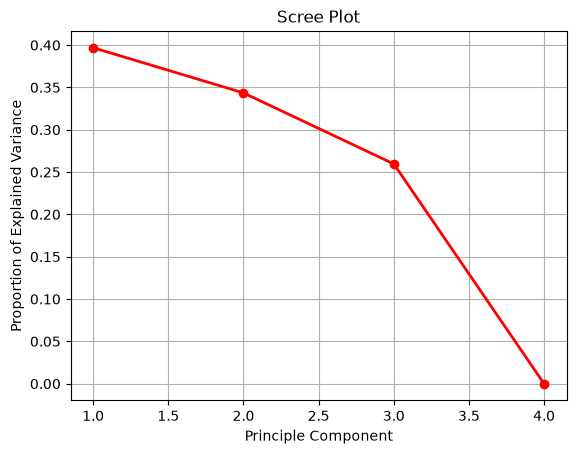

In [6]:
pca_redo_values = np.arange(pca_redo.n_components_) + 1
plt.plot(pca_redo_values,
         pca_redo.explained_variance_ratio_,
         'ro-',
         linewidth = 2
         )

plt.title('Scree Plot')
plt.xlabel('Principle Component')
plt.ylabel('Proportion of Explained Variance')
plt.grid('both')
plt.show

In [7]:
pca_redo_loadings = pd.DataFrame(
    pca_redo.components_.T, #Transposes the pca_redo matrix.
    columns = [f'PC{i+1}' for i in range(pca_redo.n_components_)],
    index = copy_pcaredo_df.columns
)

pca_redo_loadings.head()

,PC1,PC2,PC3,PC4
Abditodentrix sp.,-0.115315,-0.103276,-0.034982,-0.064306
Anomalinoides incrassatus,-0.003782,0.123656,-0.124147,0.823505
Bolivina earlandi,-0.071804,0.134736,0.061344,0.454580
Bolivina seminuda,0.137555,-0.023780,-0.077402,-0.013265
Bolivina sp.,-0.115315,-0.103276,-0.034982,0.026187


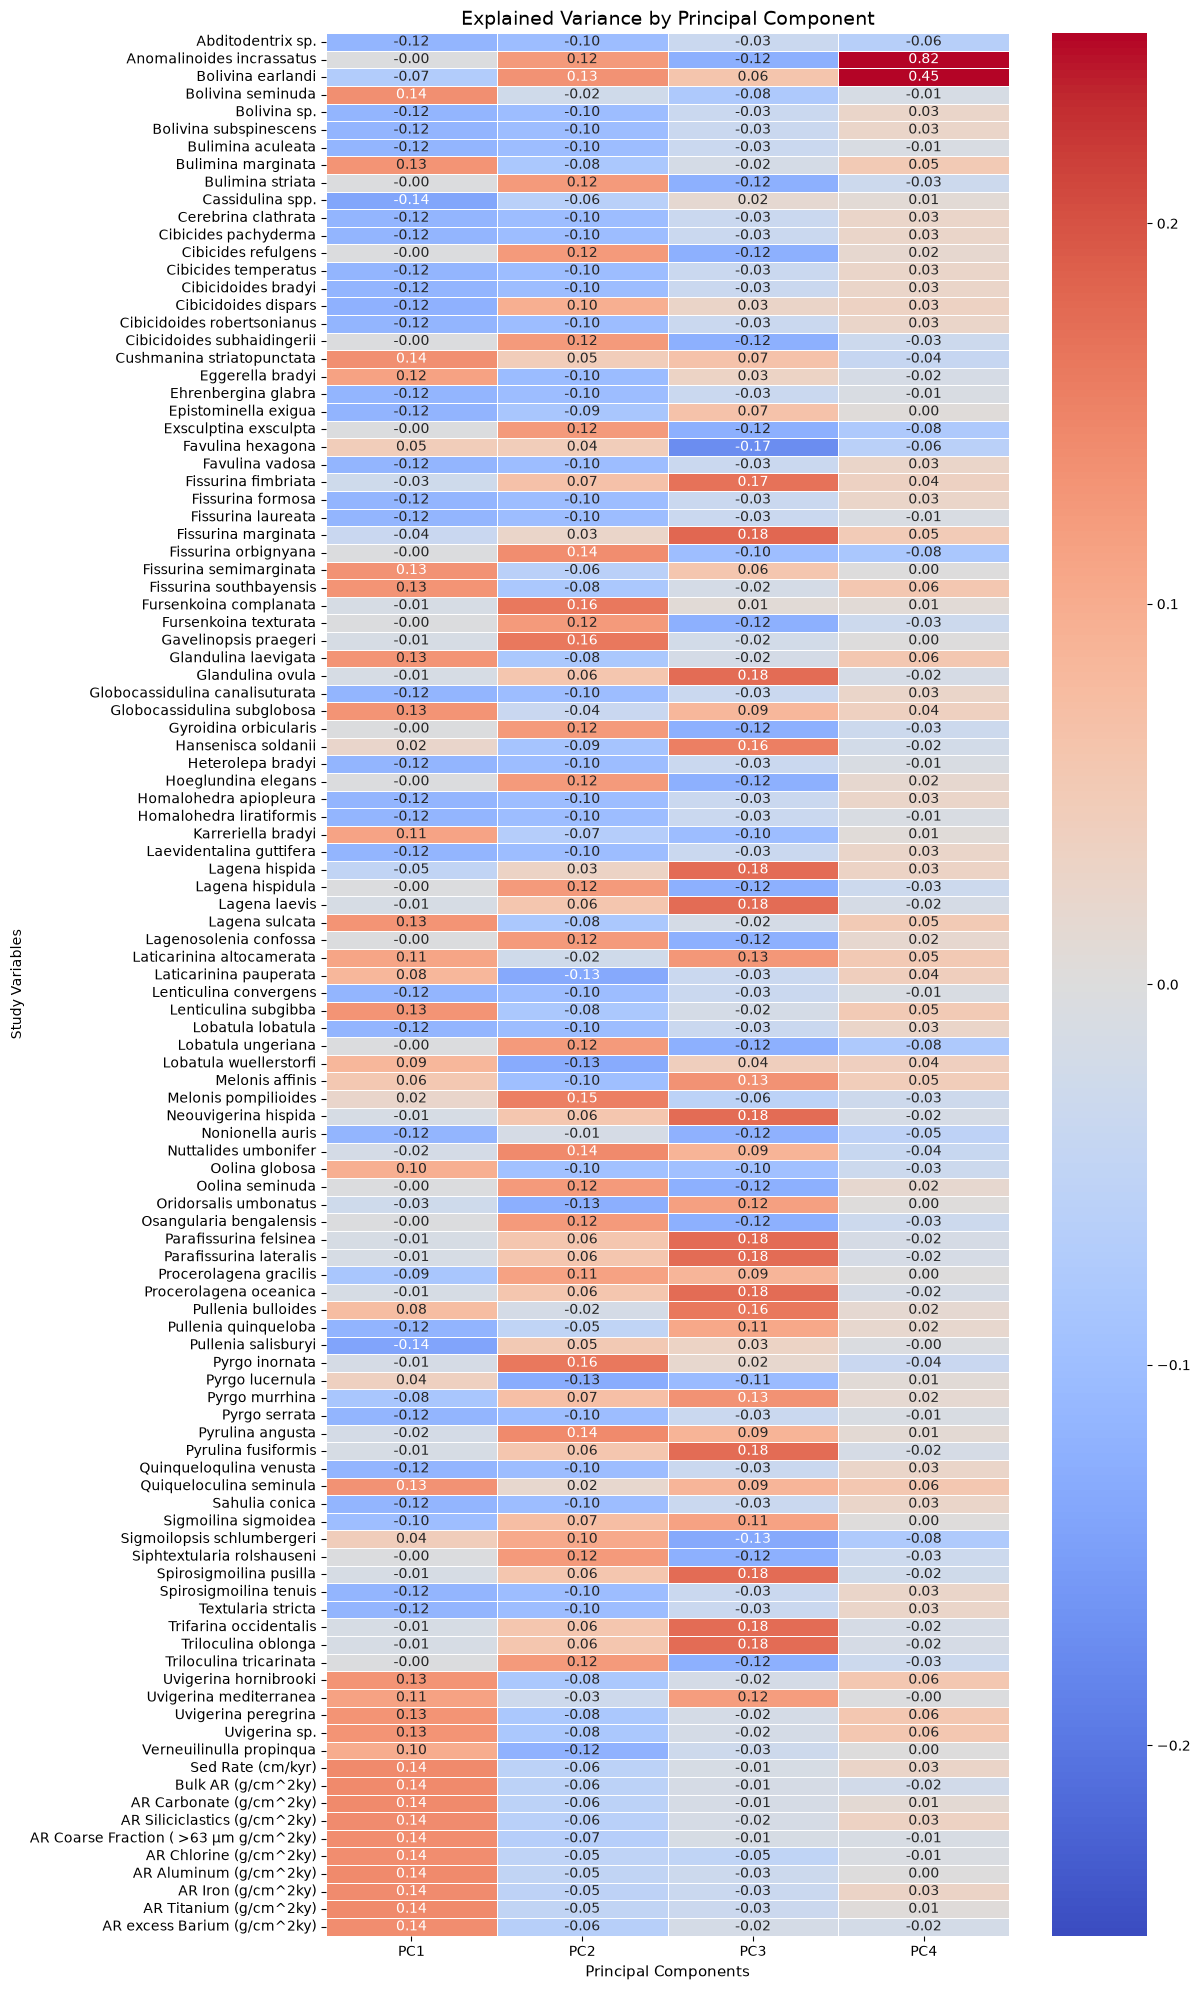

In [ ]:
fig, ax = plt.subplots(figsize = (12,20)) #Sets the figure size st the height is enough to accomodate the large amount of variables.

sns.heatmap(
    pca_redo_loadings, # Dataframe input
    annot=True, #Allow Seaborn to write on the plot
    cmap = "coolwarm", #Red to Blue heatmap, choose whatever colour scheme you'd like!
    vmax=0.25, #Maximum colormap value
    vmin=-0.25, #Minimum colormap value
    center = 0, #The center can be whatever you want the color split to occur at.
    linewidth = 0.5, #Width of the line that contains the colored boxes.
    fmt = ".2f" #Keep all values to n number of decimal places.
)

ax.set_title("Explained Variance by Principal Component", fontsize = 14)
ax.set_xlabel("Principal Components", fontsize = 11)
ax.set_ylabel("Study Variables")

plt.tight_layout()
plt.show()